Quick check that the real data is intact

In [ ]:
import os

det = "/content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det"
npy = sum(len([f for f in fs if f.endswith(".npy")]) for r, d, fs in os.walk(det))
stray = sum(len([f for f in fs if f.startswith("._")]) for r, d, fs in os.walk(det))
print("npy files:", npy, "(expect 12000)")
print("stray ._ files:", stray, "(expect 0)")
print("splits:", sorted(os.listdir(det)))

npy files: 12000 (expect 12000)
stray ._ files: 0 (expect 0)
splits: ['test', 'train', 'val']


Colab wipes installed packages every session, so this reinstalls them.
My patched code and data stay in Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/CS7000_project/coperception
!grep -v mmcv requirements.txt | grep -v nuscenes-devkit > requirements_fixed.txt
!pip install -q -r requirements_fixed.txt
!pip install -q nuscenes-devkit --no-deps
!pip install -q -e . --no-deps

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/CS7000_project/coperception
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.6/78.6 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 18.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 25.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for coperception (pyproject.toml) ... done


Check the code loads.
Confirms that my patched files and the Linux mapping file work in this fresh session before I spend GPU time.

In [ ]:
!python -c "import coperception; from coperception.utils.mean_ap import eval_map; print('all imports OK')"

all imports OK


Look up the evaluation command's options.
I need the exact option names and my checkpoint file paths so the evaluation command is correct, not guessed.

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception
!python tools/det/test_codet.py --help
!find /content/drive/MyDrive/CS7000_project/checkpoints -name "*.pth"

/content/drive/MyDrive/CS7000_project/coperception
/content/drive/MyDrive/CS7000_project/coperception/coperception/utils/min_norm_solvers.py:44: SyntaxWarning: invalid escape sequence '\s'
  ie. min_c |\sum c_i x_i|_2^2 st. \sum c_i = 1 , 1 >= c_1 >= 0 for all i, c_i + c_j = 1.0 for some i, j
/content/drive/MyDrive/CS7000_project/coperception/coperception/utils/min_norm_solvers.py:72: SyntaxWarning: invalid escape sequence '\s'
  Given y, it solves argmin_z |y-z|_2 st \sum z = 1 , 1 >= z_i >= 0 for all i
/content/drive/MyDrive/CS7000_project/coperception/coperception/utils/min_norm_solvers.py:105: SyntaxWarning: invalid escape sequence '\s'
  as min |u|_2 st. u = \sum c_i vecs[i] and \sum c_i = 1.
/content/drive/MyDrive/CS7000_project/coperception/coperception/utils/min_norm_solvers.py:151: SyntaxWarning: invalid escape sequence '\s'
  as min |u|_2 st. u = \sum c_i vecs[i] and \sum c_i = 1.
usage: test_codet.py [-h] [-d DATA] [--nepoch NEPOCH] [--nworker NWORKER]
                     [

I couldn't recover the exact command from my earlier evaluation, so read the script's own settings instead of guessing.

# Check the script's defaults

In [ ]:
!grep -n "add_argument\|num_agent\|args.rsu\|args.inference\|args.data\|args.com ==" tools/det/test_codet.py | head -80

42:    config.inference = args.inference
43:    if args.com == "upperbound":
45:    elif args.com == "when2com":
47:        if args.inference == "argmax_test":
53:    elif args.com == "lowerbound":
64:    num_agent = args.num_agent
66:    agent_idx_range = range(num_agent) if args.rsu else range(1, num_agent)
68:        dataset_roots=[f"{args.data}/agent{i}" for i in agent_idx_range],
73:        bound="upperbound" if args.com == "upperbound" else "lowerbound",
75:        rsu=args.rsu,
82:    if not args.rsu:
83:        num_agent -= 1
87:            config, layer=args.layer, kd_flag=args.kd_flag, num_agent=num_agent
95:            num_agent=num_agent,
99:    elif args.com == "disco":
104:            num_agent=num_agent,
108:    elif args.com == "sum":
113:            num_agent=num_agent,
117:    elif args.com == "mean":
122:            num_agent=num_agent,
126:    elif args.com == "max":
131:            num_agent=num_agent,
135:    elif args.com == "cat":
140:            num_agent=num_a

Check the when2com setting and where results are saved

In [ ]:
!sed -n '38,62p;395,412p' tools/det/test_codet.py

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    device_num = torch.cuda.device_count()
    print("device number", device_num)

    config.inference = args.inference
    if args.com == "upperbound":
        flag = "upperbound"
    elif args.com == "when2com":
        flag = "when2com"
        if args.inference == "argmax_test":
            flag = "who2com"
        if args.warp_flag:
            flag = flag + "_warp"
    elif args.com in {"v2v", "disco", "sum", "mean", "max", "cat", "agent"}:
        flag = args.com
    elif args.com == "lowerbound":
        flag = "lowerbound"
        if args.box_com:
            flag += "_box_com"
    else:
        raise ValueError(f"com: {args.com} is not supported")

    print("flag", flag)
    config.flag = flag
    config.split = "test"

            # restore data before late-fusion
            if apply_late_fusion == 1 and len(result[k]) != 0:
                result[k][0][0][0]["pred"] = pred_restore
                r

# Run the evaluation for the first model (lowerbound)

This runs the pretrained single-vehicle model on your 1,800 test frames. We try the simplest model first, so any problem shows up before the bigger ones.

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com lowerbound \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 2>&1 | tail -n 40

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-----+------+--------+-------+
| class | gts | dets | recall | ap    |
+-------+-----+------+--------+-------+
| 0     | 479 | 259  | 0.507  | 0.505 |
+-------+-----+------+--------+-------+
| mAP   |     |      |        | 0.505 |
+-------+-----+------+--------+-------+
Local mAP@0.7 from agent 4

+-------+-----+------+--------+-------+
| class | gts | dets | recall | ap    |
+-------+-----+------+--------+-------+
| 0     | 479 | 259  | 0.480  | 0.474 |
+-------+-----+------+--------+-------+
| mAP   |     |      |        | 0.474 |
+-------+-----+------+--------+-------+

+-------+-------+------+--------+-------+
| class | gts   | dets | recall | ap    |
+-------+-------+------+--------+-------+
| 0     | 12978 | 7856 | 0.559  | 0.554 |
+-------+-------+------+--------+-------+
| mAP   |       |      |        | 0.554 |
+-------+-------+------+--------+-------+

+-------+-------+------+--------+-------+
| class | gt

#Run the evaluation for V2Vnet

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com v2v \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/v2v/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 2>&1 | tail -n 40

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-----+------+--------+-------+
| class | gts | dets | recall | ap    |
+-------+-----+------+--------+-------+
| 0     | 479 | 389  | 0.760  | 0.759 |
+-------+-----+------+--------+-------+
| mAP   |     |      |        | 0.759 |
+-------+-----+------+--------+-------+
Local mAP@0.7 from agent 4

+-------+-----+------+--------+-------+
| class | gts | dets | recall | ap    |
+-------+-----+------+--------+-------+
| 0     | 479 | 389  | 0.737  | 0.734 |
+-------+-----+------+--------+-------+
| mAP   |     |      |        | 0.734 |
+-------+-----+------+--------+-------+

+-------+-------+-------+--------+-------+
| class | gts   | dets  | recall | ap    |
+-------+-------+-------+--------+-------+
| 0     | 12978 | 10704 | 0.759  | 0.753 |
+-------+-------+-------+--------+-------+
| mAP   |       |       |        | 0.753 |
+-------+-------+-------+--------+-------+

+-------+-------+-------+--------+-------+
| cl

#when2com has an extra --inference setting, and I want to pick the right value before spending time on a run.

In [ ]:
base = "/content/drive/MyDrive/CS7000_project/coperception"
!grep -rn "inference" {base}/coperception {base}/tools/det/test_codet.py | head -20

grep: /content/drive/MyDrive/CS7000_project/coperception/coperception/models/det/__pycache__/When2com.cpython-313.pyc: binary file matches
/content/drive/MyDrive/CS7000_project/coperception/coperception/models/det/When2com.py:159:        inference="activated",
/content/drive/MyDrive/CS7000_project/coperception/coperception/models/det/When2com.py:283:            if inference == "softmax":
/content/drive/MyDrive/CS7000_project/coperception/coperception/models/det/When2com.py:287:            elif inference == "argmax_test":
/content/drive/MyDrive/CS7000_project/coperception/coperception/models/det/When2com.py:303:            elif inference == "activated":
/content/drive/MyDrive/CS7000_project/coperception/coperception/models/det/When2com.py:329:                raise ValueError("Incorrect inference mode")
grep: /content/drive/MyDrive/CS7000_project/coperception/coperception/utils/__pycache__/CoDetModule.cpython-313.pyc: binary file matches
/content/drive/MyDrive/CS7000_project/coperception

#the last of the three models(when2com), so we can compare all of them on the same test scenes.

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com when2com \
  --inference activated \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/when2com/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 2>&1 | tail -n 40

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-----+------+--------+-------+
| class | gts | dets | recall | ap    |
+-------+-----+------+--------+-------+
| 0     | 479 | 253  | 0.476  | 0.473 |
+-------+-----+------+--------+-------+
| mAP   |     |      |        | 0.473 |
+-------+-----+------+--------+-------+
Local mAP@0.7 from agent 4

+-------+-----+------+--------+-------+
| class | gts | dets | recall | ap    |
+-------+-----+------+--------+-------+
| 0     | 479 | 253  | 0.453  | 0.447 |
+-------+-----+------+--------+-------+
| mAP   |     |      |        | 0.447 |
+-------+-----+------+--------+-------+

+-------+-------+------+--------+-------+
| class | gts   | dets | recall | ap    |
+-------+-------+------+--------+-------+
| 0     | 12915 | 6950 | 0.505  | 0.501 |
+-------+-------+------+--------+-------+
| mAP   |       |      |        | 0.501 |
+-------+-------+------+--------+-------+

+-------+-------+------+--------+-------+
| class | gt

#Limit the pictures to a sample

In [ ]:
p = "/content/drive/MyDrive/CS7000_project/coperception/tools/det/test_codet.py"
s = open(p).read()
old = "            if args.visualization:\n                visualization("
new = "            if args.visualization and str(idx).isdigit() and int(idx) % 25 == 0:\n                visualization("
print("occurrences found:", s.count(old))
if s.count(old) == 1:
    open(p, "w").write(s.replace(old, new))
    print("patched")

occurrences found: 1
patched


#Run lowerbound again with pictures turned on

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com lowerbound \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 \
  --visualization 1 2>&1 | tail -n 15

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-------+------+--------+-------+
| class | gts   | dets | recall | ap    |
+-------+-------+------+--------+-------+
| 0     | 12978 | 7856 | 0.502  | 0.491 |
+-------+-------+------+--------+-------+
| mAP   |       |      |        | 0.491 |
+-------+-------+------+--------+-------+
Quantitative evaluation results of model from /content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu/epoch_100.pth, at epoch 100
agent1 mAP@0.5 is 0.5454081296920776 and mAP@0.7 is 0.5038480162620544
agent2 mAP@0.5 is 0.7001507878303528 and mAP@0.7 is 0.6420509219169617
agent3 mAP@0.5 is 0.6263898611068726 and mAP@0.7 is 0.5261087417602539
agent4 mAP@0.5 is 0.33487680554389954 and mAP@0.7 is 0.2727116048336029
agent5 mAP@0.5 is 0.505272388458252 and mAP@0.7 is 0.4739476144313812
average local mAP@0.5 is 0.553817629814148 and average local mAP@0.7 is 0.49058428406715393


#Check the pictures were created

pictures: 60
['/content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu/vis1/19/0.png', '/content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu/vis1/19/25.png', '/content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu/vis1/19/50.png']


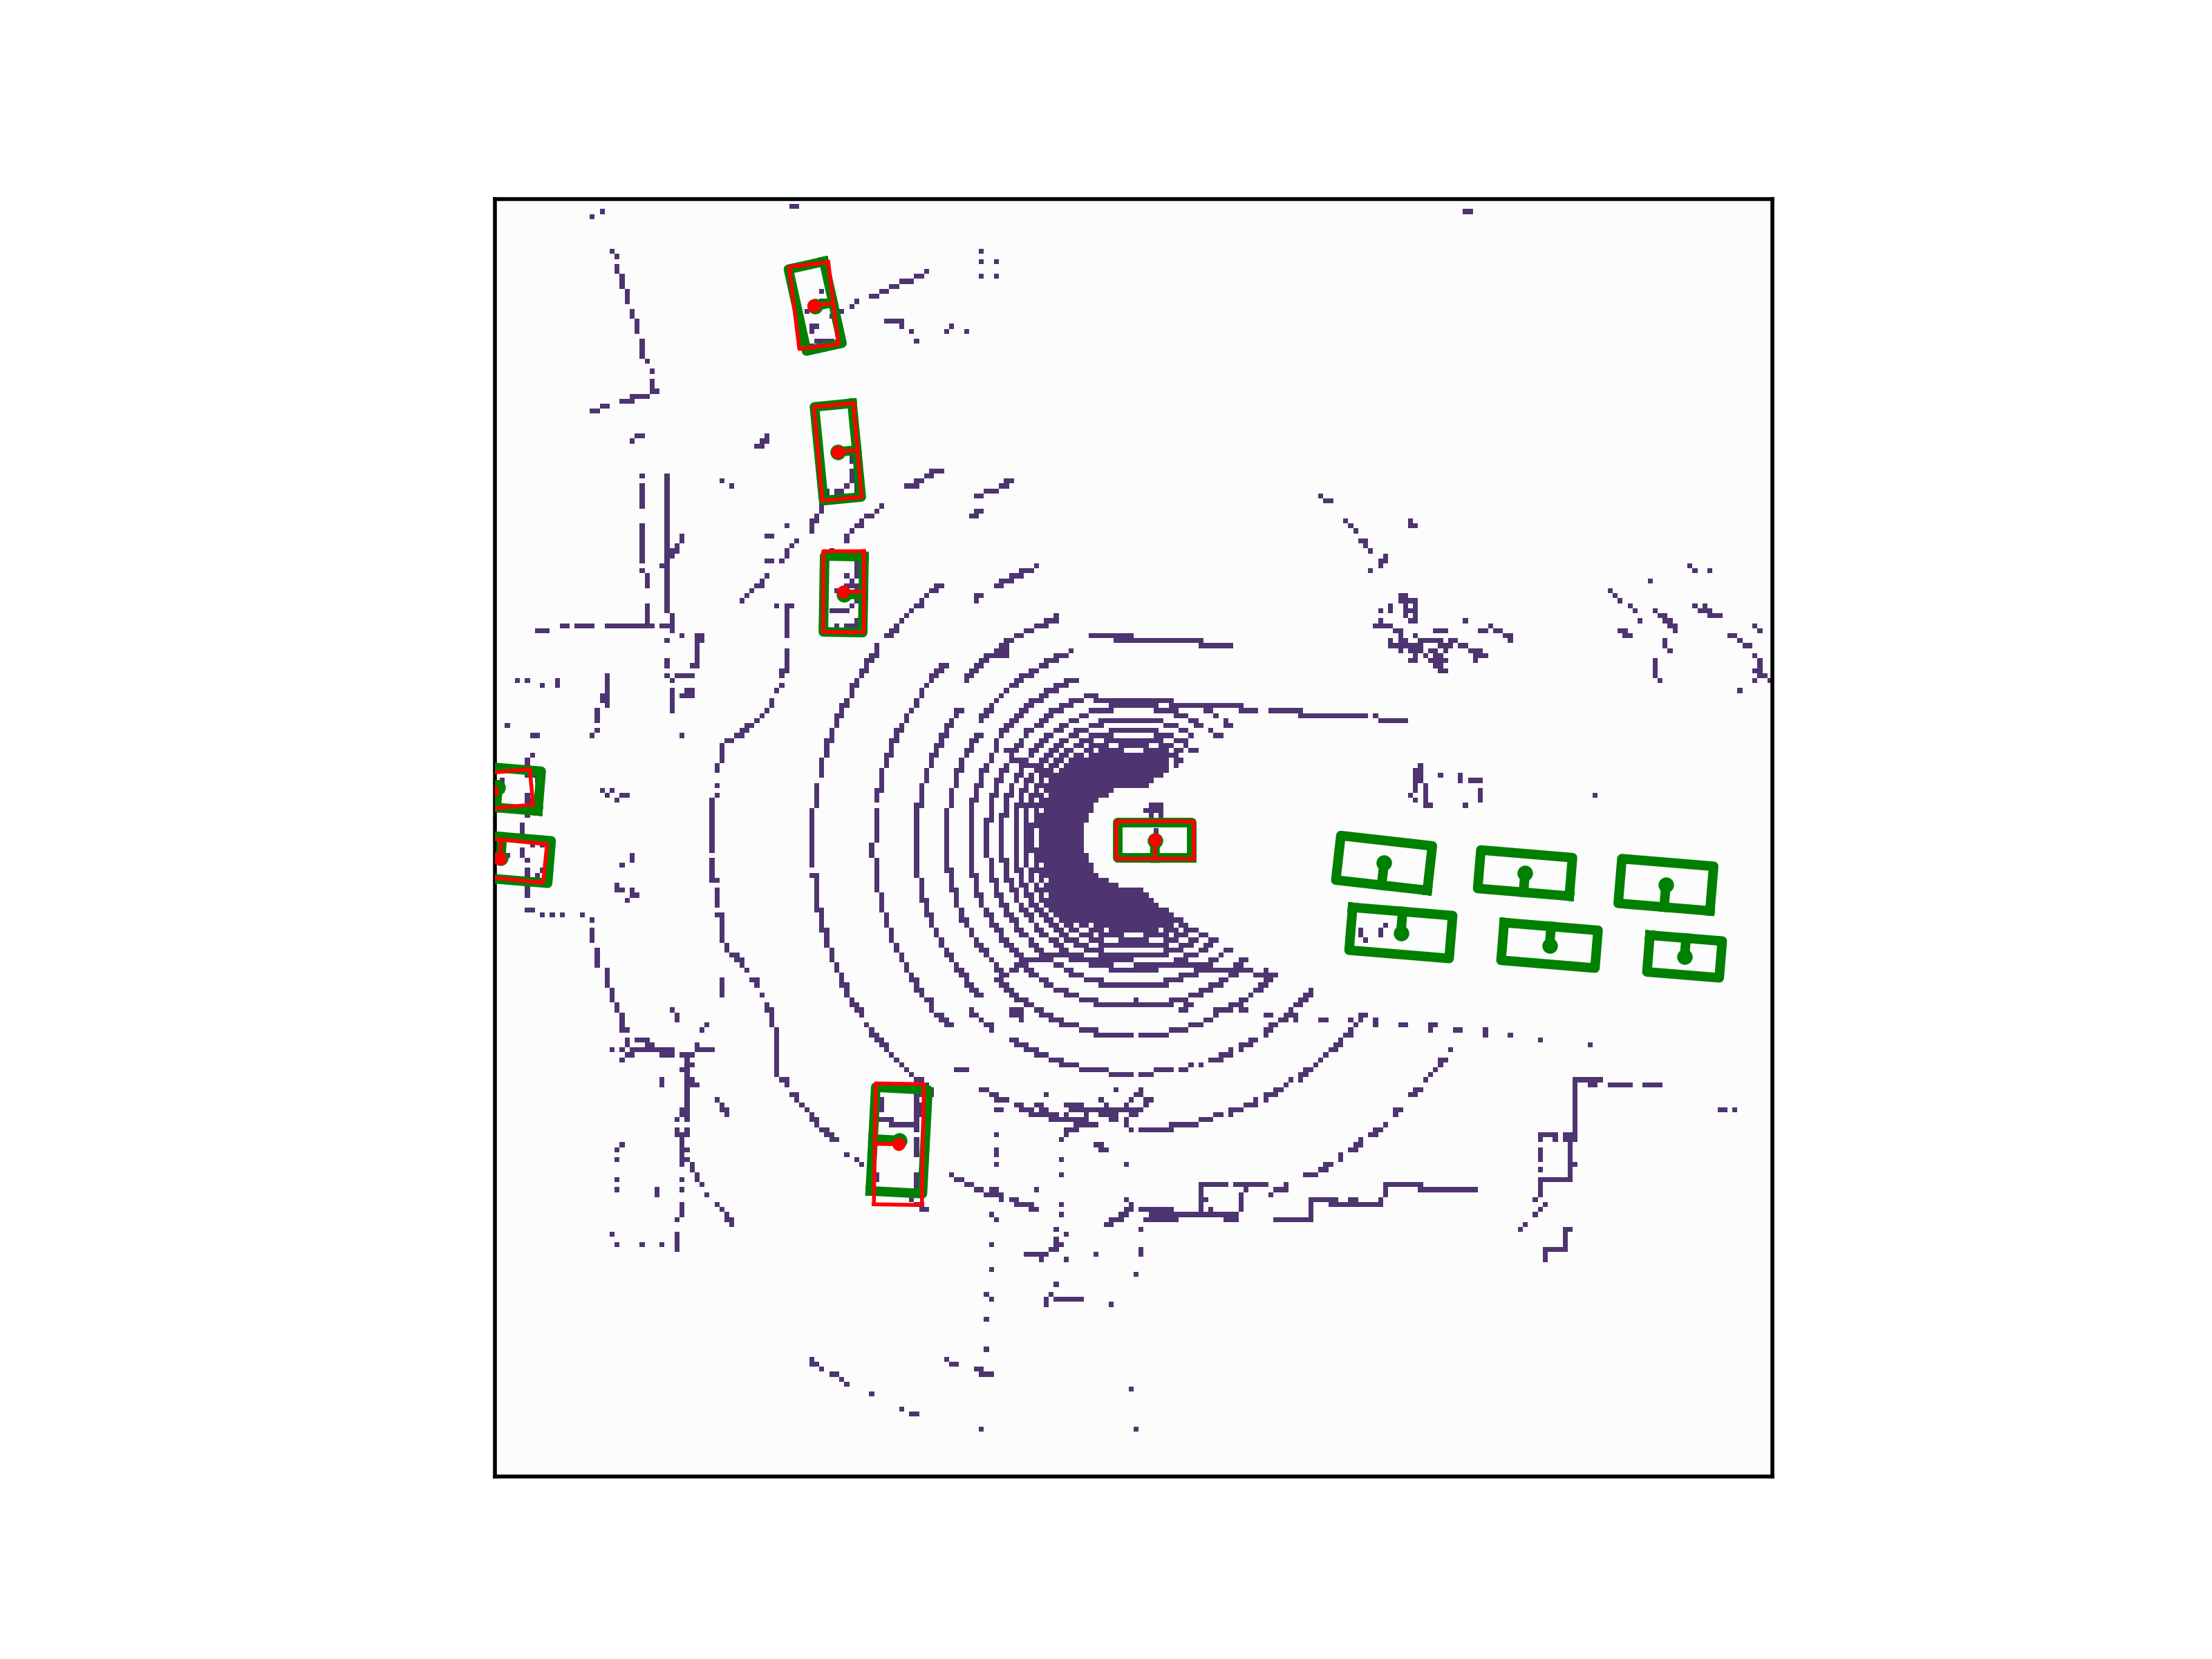

In [ ]:
import glob
from IPython.display import Image, display

ck = "/content/drive/MyDrive/CS7000_project/checkpoints/det/lowerbound/no_rsu"
pngs = sorted(glob.glob(f"{ck}/vis*/**/*.png", recursive=True))
print("pictures:", len(pngs))
print(pngs[:3])
display(Image(pngs[0]))

#Run V2VNet with pictures

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com v2v \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/v2v/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 \
  --visualization 1 2>&1 | tail -n 15

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-------+-------+--------+-------+
| class | gts   | dets  | recall | ap    |
+-------+-------+-------+--------+-------+
| 0     | 12978 | 10704 | 0.726  | 0.715 |
+-------+-------+-------+--------+-------+
| mAP   |       |       |        | 0.715 |
+-------+-------+-------+--------+-------+
Quantitative evaluation results of model from /content/drive/MyDrive/CS7000_project/checkpoints/det/v2v/no_rsu/epoch_100.pth, at epoch 100
agent1 mAP@0.5 is 0.7498307228088379 and mAP@0.7 is 0.7328236103057861
agent2 mAP@0.5 is 0.8683285713195801 and mAP@0.7 is 0.8356127142906189
agent3 mAP@0.5 is 0.788714587688446 and mAP@0.7 is 0.7597297430038452
agent4 mAP@0.5 is 0.5889049172401428 and mAP@0.7 is 0.5080050826072693
agent5 mAP@0.5 is 0.7587181925773621 and mAP@0.7 is 0.7341499924659729
average local mAP@0.5 is 0.7529487609863281 and average local mAP@0.7 is 0.715049147605896


#Run when2com with pictures

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com when2com \
  --inference activated \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/when2com/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 \
  --visualization 1 2>&1 | tail -n 15

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-------+------+--------+-------+
| class | gts   | dets | recall | ap    |
+-------+-------+------+--------+-------+
| 0     | 12915 | 6950 | 0.474  | 0.465 |
+-------+-------+------+--------+-------+
| mAP   |       |      |        | 0.465 |
+-------+-------+------+--------+-------+
Quantitative evaluation results of model from /content/drive/MyDrive/CS7000_project/checkpoints/det/when2com/no_rsu/epoch_100.pth, at epoch 100
agent1 mAP@0.5 is 0.5353366136550903 and mAP@0.7 is 0.494585782289505
agent2 mAP@0.5 is 0.6768643856048584 and mAP@0.7 is 0.602637529373169
agent3 mAP@0.5 is 0.487174391746521 and mAP@0.7 is 0.47759348154067993
agent4 mAP@0.5 is 0.2778283357620239 and mAP@0.7 is 0.2644963264465332
agent5 mAP@0.5 is 0.4727064073085785 and mAP@0.7 is 0.4472115933895111
average local mAP@0.5 is 0.5007995963096619 and average local mAP@0.7 is 0.4647520184516907


#put the three models side by side on the frame and save the figure

Side-by-side detections from the single-vehicle lowerbound, V2VNet and when2com on the same frames. Green boxes are ground truth and red boxes are model detections. Frames 0 and 50 are used because they show the clearest gap: V2VNet recovers distant vehicles that the lowerbound misses, and when2com recovers fewer. Output is saved to results/figures/final_scene19_agent4_2x3.png for the report.

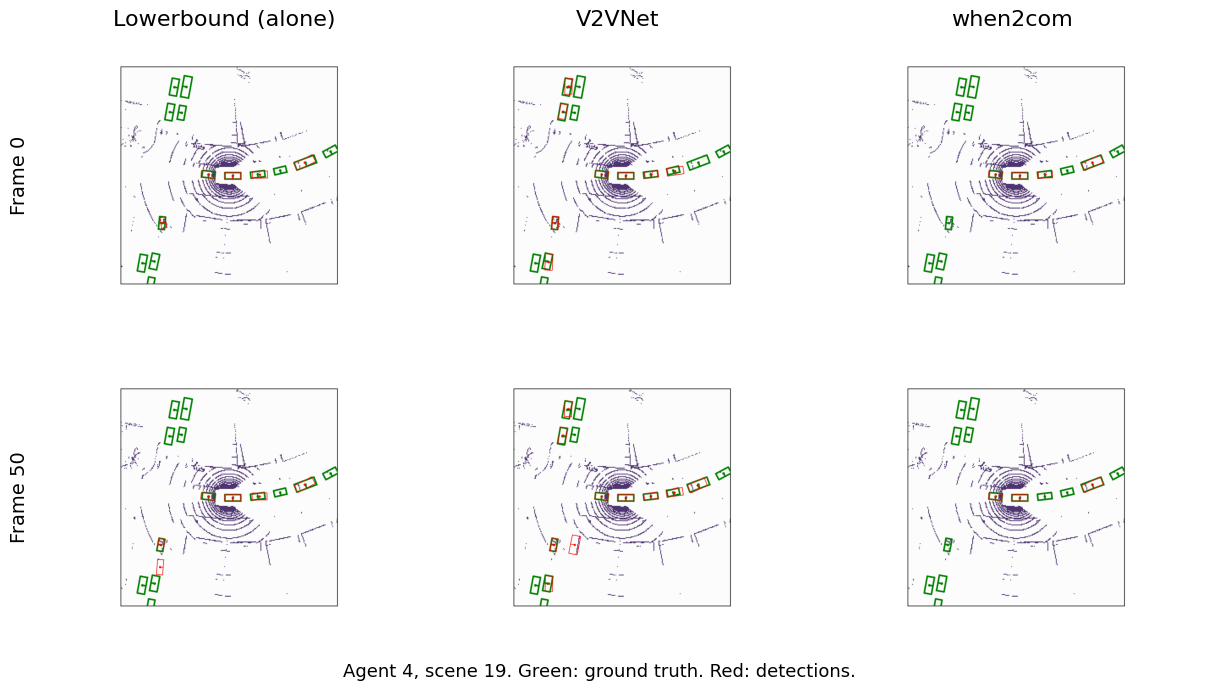

In [ ]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
base = "/content/drive/MyDrive/CS7000_project"
models = [("lowerbound", "Lowerbound (alone)"), ("v2v", "V2VNet"), ("when2com", "when2com")]
frames = [0, 50]
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5))
for r, f in enumerate(frames):
    for c, (m, title) in enumerate(models):
        axs[r][c].imshow(mpimg.imread(f"{base}/checkpoints/det/{m}/no_rsu/vis4/19/{f}.png"))
        axs[r][c].axis("off")
        if r == 0:
            axs[r][c].set_title(title, fontsize=16)
    axs[r][0].text(-0.02, 0.5, f"Frame {f}", transform=axs[r][0].transAxes,
                   rotation=90, va="center", ha="right", fontsize=14)
plt.subplots_adjust(hspace=0.02, wspace=0.05, bottom=0.03)
fig.text(0.5, 0.0, "Agent 4, scene 19. Green: ground truth. Red: detections.", ha="center", fontsize=13)
plt.savefig(f"{base}/results/figures/final_scene19_agent4_2x3.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
%cd /content/drive/MyDrive/CS7000_project/coperception/tools/det
!python test_codet.py \
  --data /content/drive/MyDrive/CS7000_project/v2x_sim_20scenes_det/test \
  --com when2com --inference activated --warp_flag 1 \
  --resume /content/drive/MyDrive/CS7000_project/checkpoints/det/when2com/no_rsu/epoch_100.pth \
  --logpath /content/drive/MyDrive/CS7000_project/results \
  --rsu 0 2>&1 | tail -n 15

/content/drive/MyDrive/CS7000_project/coperception/tools/det

+-------+-------+------+--------+-------+
| class | gts   | dets | recall | ap    |
+-------+-------+------+--------+-------+
| 0     | 12927 | 6892 | 0.469  | 0.460 |
+-------+-------+------+--------+-------+
| mAP   |       |      |        | 0.460 |
+-------+-------+------+--------+-------+
Quantitative evaluation results of model from /content/drive/MyDrive/CS7000_project/checkpoints/det/when2com/no_rsu/epoch_100.pth, at epoch 100
agent1 mAP@0.5 is 0.53872150182724 and mAP@0.7 is 0.48906946182250977
agent2 mAP@0.5 is 0.6772428750991821 and mAP@0.7 is 0.5995454788208008
agent3 mAP@0.5 is 0.475997656583786 and mAP@0.7 is 0.4659672975540161
agent4 mAP@0.5 is 0.2726488411426544 and mAP@0.7 is 0.26503127813339233
agent5 mAP@0.5 is 0.47267377376556396 and mAP@0.7 is 0.4472155272960663
average local mAP@0.5 is 0.49798014760017395 and average local mAP@0.7 is 0.45982635021209717


#pulling per-agent AP for all three models into one place

In [ ]:
import re
base = "/content/drive/MyDrive/CS7000_project/results"
for m in ["lowerbound", "v2v", "when2com"]:
    print("==", m)
    with open(f"{base}/{m}_eval/no_rsu/log_test.txt") as f:
        lines = [l.strip() for l in f if re.match(r"(agent\d mAP|average local)", l.strip())]
    print("\n".join(lines[-6:]))

== lowerbound
agent1 mAP@0.5 is 0.5454081296920776 and mAP@0.7 is 0.5038480162620544
agent2 mAP@0.5 is 0.7001507878303528 and mAP@0.7 is 0.6420509219169617
agent3 mAP@0.5 is 0.6263898611068726 and mAP@0.7 is 0.5261087417602539
agent4 mAP@0.5 is 0.33487680554389954 and mAP@0.7 is 0.2727116048336029
agent5 mAP@0.5 is 0.505272388458252 and mAP@0.7 is 0.4739476144313812
average local mAP@0.5 is 0.553817629814148 and average local mAP@0.7 is 0.49058428406715393
== v2v
agent1 mAP@0.5 is 0.7498307228088379 and mAP@0.7 is 0.7328236103057861
agent2 mAP@0.5 is 0.8683285713195801 and mAP@0.7 is 0.8356127142906189
agent3 mAP@0.5 is 0.788714587688446 and mAP@0.7 is 0.7597297430038452
agent4 mAP@0.5 is 0.5889049172401428 and mAP@0.7 is 0.5080050826072693
agent5 mAP@0.5 is 0.7587181925773621 and mAP@0.7 is 0.7341499924659729
average local mAP@0.5 is 0.7529487609863281 and average local mAP@0.7 is 0.715049147605896
== when2com
agent1 mAP@0.5 is 0.5353366136550903 and mAP@0.7 is 0.494585782289505
agent